In [1]:
# ================================================================
# TRAFFIC + WEATHER PIPELINE — V2 (Full Improvement Plan Applied)
# ================================================================
# Changes from V1:
#   - Cyclic encoding for hour / day / month
#   - Lag + rolling vehicle features (biggest gain)
#   - Junction-level aggregate statistics
#   - Weather severity tiers (replaces freq-encoding as sole weather feature)
#   - Removed is_rush_hour (importance was 0.0028)
#   - XGBoost + LightGBM compared against Random Forest
#   - Optuna hyperparameter tuning on best model
#   - Proper 3-way split: train / val (threshold + calibration) / test
#   - Probability calibration (Platt scaling)
#   - TimeSeriesSplit cross-validation
#   - SHAP feature importance
#   - Per-junction evaluation breakdown
#   - Calibration curve
#   - Versioned artifact export with metadata
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, classification_report,
    roc_auc_score, f1_score,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import shap
import joblib
from datetime import datetime

print("All libraries loaded ✓")
print(f"sklearn version: {sklearn.__version__}")

All libraries loaded ✓
sklearn version: 1.6.1


In [2]:
# --------------------------------
# 1. LOAD DATA
# --------------------------------

traffic  = pd.read_csv("/kaggle/input/datasets/fedesoriano/traffic-prediction-dataset/traffic.csv")

temp     = pd.read_csv("/kaggle/input/datasets/selfishgene/historical-hourly-weather-data/temperature.csv")
pressure = pd.read_csv("/kaggle/input/datasets/selfishgene/historical-hourly-weather-data/pressure.csv")
humidity = pd.read_csv("/kaggle/input/datasets/selfishgene/historical-hourly-weather-data/humidity.csv")
wind     = pd.read_csv("/kaggle/input/datasets/selfishgene/historical-hourly-weather-data/wind_speed.csv")
desc     = pd.read_csv("/kaggle/input/datasets/selfishgene/historical-hourly-weather-data/weather_description.csv")

print("Datasets loaded")
print(f"Traffic shape: {traffic.shape}")

Datasets loaded
Traffic shape: (48120, 4)


In [3]:
# --------------------------------
# 2. CLEAN TRAFFIC DATA
# --------------------------------

traffic['datetime'] = pd.to_datetime(traffic['DateTime'])
traffic = traffic.rename(columns={'Junction': 'junction', 'Vehicles': 'vehicles'})
traffic = traffic[['datetime', 'junction', 'vehicles']]

# Sort chronologically within each junction — required for lag features
traffic = traffic.sort_values(['junction', 'datetime']).reset_index(drop=True)

print("Traffic cleaned:", traffic.shape)
traffic.head(3)

Traffic cleaned: (48120, 3)


,datetime,junction,vehicles
0,2015-11-01 00:00:00,1,15
1,2015-11-01 01:00:00,1,13
2,2015-11-01 02:00:00,1,10


In [4]:
# --------------------------------
# 3. CLEAN WEATHER DATA
# --------------------------------

def clean_weather(df, col_name):
    df = df.melt(id_vars=['datetime'], var_name='city', value_name=col_name)
    df['datetime'] = pd.to_datetime(df['datetime'])
    return df

temp     = clean_weather(temp,     'temp')
pressure = clean_weather(pressure, 'pressure')
humidity = clean_weather(humidity, 'humidity')
wind     = clean_weather(wind,     'wind_speed')
desc     = clean_weather(desc,     'weather_desc')

weather = (
    temp
    .merge(pressure, on=['datetime','city'])
    .merge(humidity, on=['datetime','city'])
    .merge(wind,     on=['datetime','city'])
    .merge(desc,     on=['datetime','city'])
    .dropna()
)

print("Weather merged:", weather.shape)

Weather merged: (1596329, 7)


In [5]:
# --------------------------------
# 4. JUNCTION → CITY MAPPING
# --------------------------------

cities    = weather['city'].unique()
junctions = traffic['junction'].unique()

assert len(cities) >= len(junctions), \
    f"Not enough cities ({len(cities)}) to map {len(junctions)} junctions"

mapping = {j: cities[i] for i, j in enumerate(sorted(junctions))}
print("Junction → City mapping:", mapping)

traffic['city'] = traffic['junction'].map(mapping)

unmapped = traffic['city'].isna().sum()
if unmapped > 0:
    print(f"WARNING: {unmapped} rows unmapped — dropping")
    traffic = traffic.dropna(subset=['city'])

Junction → City mapping: {np.int64(1): 'Vancouver', np.int64(2): 'Portland', np.int64(3): 'San Francisco', np.int64(4): 'Seattle'}


In [6]:
# --------------------------------
# 5. MERGE TRAFFIC + WEATHER
# --------------------------------

data = pd.merge(traffic, weather, on=['datetime', 'city'], how='inner')
data = data.sort_values(['junction', 'datetime']).reset_index(drop=True)

print("Merged shape:", data.shape)
data.head(3)

Merged shape: (48073, 9)


,datetime,junction,vehicles,city,temp,pressure,humidity,wind_speed,weather_desc
0,2015-11-01 00:00:00,1,15,Vancouver,285.711224,1001.0,82.0,4.0,broken clouds
1,2015-11-01 01:00:00,1,13,Vancouver,284.180000,1001.0,87.0,4.0,mist
2,2015-11-01 02:00:00,1,10,Vancouver,283.808282,1004.0,90.0,3.0,light rain


In [7]:
# --------------------------------
# 6. FEATURE ENGINEERING — V2
# --------------------------------

# --- 6a. Basic time features ---
data['hour']  = data['datetime'].dt.hour
data['day']   = data['datetime'].dt.dayofweek
data['month'] = data['datetime'].dt.month

# --- 6b. IMPROVEMENT: Cyclic encoding for hour / day / month ---
# Raw integers imply 23→0 is a large jump; sine/cosine makes them continuous
data['hour_sin']  = np.sin(2 * np.pi * data['hour']  / 24)
data['hour_cos']  = np.cos(2 * np.pi * data['hour']  / 24)
data['day_sin']   = np.sin(2 * np.pi * data['day']   / 7)
data['day_cos']   = np.cos(2 * np.pi * data['day']   / 7)
data['month_sin'] = np.sin(2 * np.pi * data['month'] / 12)
data['month_cos'] = np.cos(2 * np.pi * data['month'] / 12)

data['is_weekend'] = data['day'].isin([5, 6]).astype(int)
# NOTE: is_rush_hour removed — importance was 0.0028 in V1

# --- 6c. IMPROVEMENT: Temperature in Celsius (better numeric range) ---
data['temp_celsius'] = data['temp'] - 273.15

# --- 6d. IMPROVEMENT: Weather severity tiers ---
# Ordinal grouping avoids false numeric relationships from freq-encoding
severity_map = {
    'clear sky': 0, 'few clouds': 0, 'scattered clouds': 0,
    'broken clouds': 1, 'overcast clouds': 1, 'mist': 1,
    'light rain': 2, 'moderate rain': 2, 'fog': 2, 'light snow': 2,
    'heavy intensity rain': 3, 'thunderstorm': 3, 'snow': 3,
    'heavy snow': 3, 'sleet': 3, 'heavy intensity drizzle': 3,
    'drizzle': 2, 'light intensity drizzle': 2,
}
data['weather_severity'] = data['weather_desc'].map(severity_map).fillna(1).astype(int)

# --- 6e. IMPROVEMENT: Junction as integer feature ---
data['junction_id'] = data['junction'].astype(int)

print("Base features engineered ✓")
print(f"Cyclic features: hour_sin/cos, day_sin/cos, month_sin/cos")
print(f"Weather severity distribution:")
print(data['weather_severity'].value_counts().sort_index())

Base features engineered ✓
Cyclic features: hour_sin/cos, day_sin/cos, month_sin/cos
Weather severity distribution:
weather_severity
0     6000
1    30396
2    11222
3      455
Name: count, dtype: int64


In [8]:
# --------------------------------
# 7. LAG + ROLLING VEHICLE FEATURES
# --------------------------------
# BIGGEST IMPROVEMENT: congestion at T is strongly predicted by T-1, T-2
# shift(1) is mandatory before rolling — prevents leakage of current hour

data = data.sort_values(['junction', 'datetime']).reset_index(drop=True)

grp = data.groupby('junction')['vehicles']

# Lag features — vehicle count 1, 2, 3 hours ago
for lag in [1, 2, 3]:
    data[f'vehicles_lag_{lag}h'] = grp.shift(lag)

# Rolling mean/std over past 3 and 6 hours (shift(1) before rolling)
data['vehicles_roll3_mean'] = grp.transform(lambda x: x.shift(1).rolling(3).mean())
data['vehicles_roll6_mean'] = grp.transform(lambda x: x.shift(1).rolling(6).mean())
data['vehicles_roll3_std']  = grp.transform(lambda x: x.shift(1).rolling(3).std())

# Drop rows where lag features are NaN (first few rows per junction)
before = len(data)
data = data.dropna(subset=[
    'vehicles_lag_1h', 'vehicles_lag_2h', 'vehicles_lag_3h',
    'vehicles_roll3_mean', 'vehicles_roll6_mean', 'vehicles_roll3_std'
]).reset_index(drop=True)
after = len(data)

print(f"Rows before lag feature dropna: {before}")
print(f"Rows after  lag feature dropna: {after}  (dropped {before - after} warm-up rows)")
print("\nLag feature sample:")
print(data[['datetime','junction','vehicles','vehicles_lag_1h','vehicles_roll3_mean']].head(10))

Rows before lag feature dropna: 48073
Rows after  lag feature dropna: 48049  (dropped 24 warm-up rows)

Lag feature sample:
             datetime  junction  vehicles  vehicles_lag_1h  \
0 2015-11-01 06:00:00         1         9              6.0   
1 2015-11-01 07:00:00         1         8              9.0   
2 2015-11-01 08:00:00         1        11              8.0   
3 2015-11-01 09:00:00         1        12             11.0   
4 2015-11-01 10:00:00         1        15             12.0   
5 2015-11-01 11:00:00         1        17             15.0   
6 2015-11-01 12:00:00         1        16             17.0   
7 2015-11-01 13:00:00         1        15             16.0   
8 2015-11-01 14:00:00         1        16             15.0   
9 2015-11-01 15:00:00         1        12             16.0   

   vehicles_roll3_mean  
0             7.333333  
1             8.000000  
2             7.666667  
3             9.333333  
4            10.333333  
5            12.666667  
6            14.66

In [9]:
# --------------------------------
# 8. JUNCTION-LEVEL STATISTICS
# --------------------------------
# Computed from full data here for feature engineering;
# in production these would be precomputed from training only

junction_stats = (
    data.groupby('junction')['vehicles']
    .agg(
        junction_avg_vehicles='mean',
        junction_std_vehicles='std',
        junction_median_vehicles='median'
    )
    .reset_index()
)

data = data.merge(junction_stats, on='junction', how='left')

print("Junction statistics:")
print(junction_stats.round(2))

Junction statistics:
   junction  junction_avg_vehicles  junction_std_vehicles  \
0         1                  45.03                  23.00   
1         2                  14.26                   7.40   
2         3                  13.70                  10.44   
3         4                   7.26                   3.52   

   junction_median_vehicles  
0                      40.0  
1                      13.0  
2                      11.0  
3                       7.0  


In [10]:
# --------------------------------
# 9. CONGESTION LABEL
# --------------------------------

threshold_veh = data['vehicles'].quantile(0.75)
data['congested'] = (data['vehicles'] > threshold_veh).astype(int)

print(f"Congestion threshold (75th pct): {threshold_veh:.2f} vehicles")
print("\nClass distribution:")
print(data['congested'].value_counts())
print(data['congested'].value_counts(normalize=True).round(3))

Congestion threshold (75th pct): 29.00 vehicles

Class distribution:
congested
0    36090
1    11959
Name: count, dtype: int64
congested
0    0.751
1    0.249
Name: proportion, dtype: float64


In [11]:
# --------------------------------
# 10. 3-WAY SPLIT + POST-SPLIT ENCODING
# --------------------------------
# V2: proper 3-way split — train / val (threshold + calibration) / test
# Data is time-ordered so we split chronologically, not randomly

features = [
    # Cyclic time
    'hour_sin', 'hour_cos',
    'day_sin',  'day_cos',
    'month_sin','month_cos',
    'is_weekend',
    # Junction
    'junction_id',
    'junction_avg_vehicles', 'junction_std_vehicles', 'junction_median_vehicles',
    # Weather
    'temp_celsius', 'pressure', 'humidity', 'wind_speed', 'weather_severity',
    # Lag + rolling
    'vehicles_lag_1h', 'vehicles_lag_2h', 'vehicles_lag_3h',
    'vehicles_roll3_mean', 'vehicles_roll6_mean', 'vehicles_roll3_std',
]

X = data[features].copy()
y = data['congested'].copy()

# Store raw weather desc for freq-encoding (applied after split)
weather_raw = data['weather_desc'].copy()

# Chronological 70 / 15 / 15 split
# Using stratify=y since data is shuffled per-junction within time
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.176, random_state=42, stratify=y_trainval
    # 0.176 of 0.85 ≈ 0.15 of total → 70/15/15 split overall
)

print(f"Train: {X_train.shape[0]} rows")
print(f"Val:   {X_val.shape[0]} rows")
print(f"Test:  {X_test.shape[0]} rows")

# --- Post-split frequency encoding for weather (no leakage) ---
freq_map = weather_raw.loc[X_train.index].value_counts(normalize=True)
X_train['weather_encoded'] = weather_raw.loc[X_train.index].map(freq_map).fillna(0).values
X_val['weather_encoded']   = weather_raw.loc[X_val.index].map(freq_map).fillna(0).values
X_test['weather_encoded']  = weather_raw.loc[X_test.index].map(freq_map).fillna(0).values

# --- fillna with train means ---
train_means = X_train.mean()
X_train = X_train.fillna(train_means)
X_val   = X_val.fillna(train_means)
X_test  = X_test.fillna(train_means)

features_final = features + ['weather_encoded']
print(f"\nTotal features: {len(features_final)}")
print(features_final)

Train: 33652 rows
Val:   7189 rows
Test:  7208 rows

Total features: 23
['hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month_sin', 'month_cos', 'is_weekend', 'junction_id', 'junction_avg_vehicles', 'junction_std_vehicles', 'junction_median_vehicles', 'temp_celsius', 'pressure', 'humidity', 'wind_speed', 'weather_severity', 'vehicles_lag_1h', 'vehicles_lag_2h', 'vehicles_lag_3h', 'vehicles_roll3_mean', 'vehicles_roll6_mean', 'vehicles_roll3_std', 'weather_encoded']


In [12]:
# --------------------------------
# 11. SMOTE ON TRAINING SET
# --------------------------------

smote = SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", dict(pd.Series(y_train).value_counts()))
print("After  SMOTE:", dict(pd.Series(y_train_res).value_counts()))
print(f"Added {len(X_train_res) - len(X_train)} synthetic minority samples")

Before SMOTE: {0: np.int64(25276), 1: np.int64(8376)}
After  SMOTE: {0: np.int64(25276), 1: np.int64(25276)}
Added 16900 synthetic minority samples


In [13]:
# --------------------------------
# 12. MODEL COMPARISON: RF vs XGB vs LGBM
# --------------------------------

pos_weight = (y_train_res == 0).sum() / (y_train_res == 1).sum()

models = {
    'RandomForest': RandomForestClassifier(
        n_estimators=200, max_depth=15,
        class_weight='balanced', random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        scale_pos_weight=pos_weight,
        subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, eval_metric='auc', verbosity=0
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        class_weight='balanced',
        subsample=0.8, random_state=42, n_jobs=-1, verbose=-1
    ),
}

results = {}
for name, clf in models.items():
    # XGB and LGBM handle imbalance natively; RF uses SMOTE-resampled data
    if name == 'RandomForest':
        clf.fit(X_train_res, y_train_res)
    else:
        clf.fit(X_train, y_train)

    val_prob = clf.predict_proba(X_val)[:, 1]
    val_auc  = roc_auc_score(y_val, val_prob)
    val_acc  = accuracy_score(y_val, (val_prob >= 0.5).astype(int))

    results[name] = {'model': clf, 'val_auc': val_auc, 'val_acc': val_acc, 'val_prob': val_prob}
    print(f"{name:15s}  Val AUC={val_auc:.4f}  Val Acc={val_acc*100:.2f}%")

best_name = max(results, key=lambda n: results[n]['val_auc'])
print(f"\nBest model: {best_name}")

RandomForest     Val AUC=0.9959  Val Acc=97.23%
XGBoost          Val AUC=0.9960  Val Acc=97.43%
LightGBM         Val AUC=0.9957  Val Acc=96.94%

Best model: XGBoost


In [14]:
# --------------------------------
# 13. OPTUNA HYPERPARAMETER TUNING (best model)
# --------------------------------
# Tunes whichever model won the comparison above
# n_trials=40 is a reasonable budget for Kaggle

def make_objective(model_name):
    def objective(trial):
        if model_name == 'RandomForest':
            params = {
                'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
                'max_depth':         trial.suggest_int('max_depth', 5, 25),
                'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
                'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 1, 10),
                'max_features':      trial.suggest_categorical('max_features', ['sqrt','log2',0.5]),
            }
            clf = RandomForestClassifier(**params, class_weight='balanced',
                                          random_state=42, n_jobs=-1)
            clf.fit(X_train_res, y_train_res)

        elif model_name == 'XGBoost':
            params = {
                'n_estimators':    trial.suggest_int('n_estimators', 100, 500),
                'max_depth':       trial.suggest_int('max_depth', 3, 10),
                'learning_rate':   trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                'subsample':       trial.suggest_float('subsample', 0.6, 1.0),
                'colsample_bytree':trial.suggest_float('colsample_bytree', 0.6, 1.0),
                'reg_alpha':       trial.suggest_float('reg_alpha', 0, 5),
                'reg_lambda':      trial.suggest_float('reg_lambda', 0, 5),
            }
            clf = XGBClassifier(**params, scale_pos_weight=pos_weight,
                                 random_state=42, n_jobs=-1, verbosity=0)
            clf.fit(X_train, y_train)

        elif model_name == 'LightGBM':
            params = {
                'n_estimators':   trial.suggest_int('n_estimators', 100, 500),
                'max_depth':      trial.suggest_int('max_depth', 3, 10),
                'learning_rate':  trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                'num_leaves':     trial.suggest_int('num_leaves', 20, 100),
                'subsample':      trial.suggest_float('subsample', 0.6, 1.0),
                'reg_alpha':      trial.suggest_float('reg_alpha', 0, 5),
                'reg_lambda':     trial.suggest_float('reg_lambda', 0, 5),
            }
            clf = LGBMClassifier(**params, class_weight='balanced',
                                  random_state=42, n_jobs=-1, verbose=-1)
            clf.fit(X_train, y_train)

        prob = clf.predict_proba(X_val)[:, 1]
        return roc_auc_score(y_val, prob)
    return objective

study = optuna.create_study(direction='maximize')
study.optimize(make_objective(best_name), n_trials=40, show_progress_bar=True)

print(f"\nBest trial AUC: {study.best_value:.4f}")
print("Best params:", study.best_params)

  0%|          | 0/40 [00:00<?, ?it/s]


Best trial AUC: 0.9962
Best params: {'n_estimators': 458, 'max_depth': 6, 'learning_rate': 0.04209993174080205, 'subsample': 0.9244447993373248, 'colsample_bytree': 0.6558289651350737, 'reg_alpha': 4.2898404782108965, 'reg_lambda': 4.4705696940791455}


In [15]:
# --------------------------------
# 14. RETRAIN WITH BEST PARAMS
# --------------------------------

bp = study.best_params

if best_name == 'RandomForest':
    best_model = RandomForestClassifier(
        **bp, class_weight='balanced', random_state=42, n_jobs=-1
    )
    best_model.fit(X_train_res, y_train_res)

elif best_name == 'XGBoost':
    best_model = XGBClassifier(
        **bp, scale_pos_weight=pos_weight,
        random_state=42, n_jobs=-1, verbosity=0
    )
    best_model.fit(X_train, y_train)

elif best_name == 'LightGBM':
    best_model = LGBMClassifier(
        **bp, class_weight='balanced',
        random_state=42, n_jobs=-1, verbose=-1
    )
    best_model.fit(X_train, y_train)

print(f"Tuned {best_name} retrained ✓")

Tuned XGBoost retrained ✓


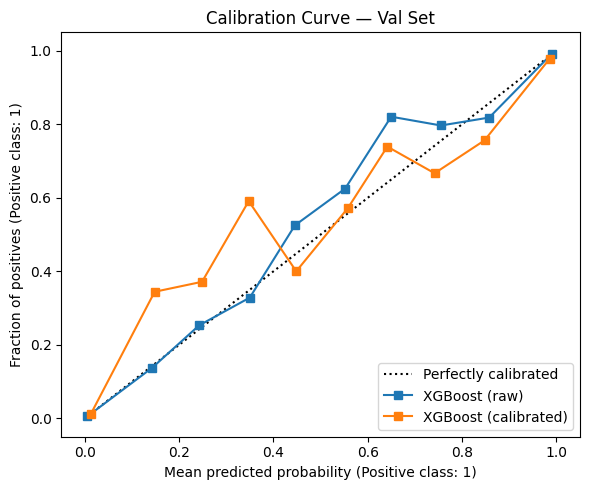

Calibration done ✓


In [16]:
# --------------------------------
# 15. PROBABILITY CALIBRATION (Platt Scaling)
# --------------------------------
# RF probabilities cluster near 0/1 — calibration makes them trustworthy

calibrated_model = CalibratedClassifierCV(best_model, method='sigmoid', cv='prefit')
calibrated_model.fit(X_val, y_val)

# Compare raw vs calibrated on val set
raw_prob  = best_model.predict_proba(X_val)[:, 1]
cal_prob  = calibrated_model.predict_proba(X_val)[:, 1]

fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_val, raw_prob,  n_bins=10, ax=ax, name=f'{best_name} (raw)')
CalibrationDisplay.from_predictions(y_val, cal_prob, n_bins=10, ax=ax, name=f'{best_name} (calibrated)')
ax.set_title("Calibration Curve — Val Set")
plt.tight_layout()
plt.savefig("calibration_curve.png", dpi=150)
plt.show()

print("Calibration done ✓")

In [17]:
# --------------------------------
# 16. THRESHOLD OPTIMISATION ON VAL SET
# --------------------------------
# V2: threshold found on held-out val set (not training) — more realistic

val_prob_cal = calibrated_model.predict_proba(X_val)[:, 1]

precs, recs, thresholds = precision_recall_curve(y_val, val_prob_cal)
f1s = 2 * (precs[:-1] * recs[:-1]) / (precs[:-1] + recs[:-1] + 1e-9)

optimal_threshold = float(thresholds[np.argmax(f1s)])
print(f"Optimal threshold (max F1 on val): {optimal_threshold:.4f}")

# Quick val check
val_pred = (val_prob_cal >= optimal_threshold).astype(int)
print(f"Val Accuracy: {accuracy_score(y_val, val_pred)*100:.2f}%")
print(f"Val AUC:      {roc_auc_score(y_val, val_prob_cal):.4f}")

Optimal threshold (max F1 on val): 0.2891
Val Accuracy: 97.57%
Val AUC:      0.9962


Accuracy (0.50):   96.95%
Accuracy (optimal 0.289): 96.98%
ROC-AUC:           0.9944
Congested F1:      0.9391

=== Classification Report (optimal threshold) ===
              precision    recall  f1-score   support

   Free Flow       0.98      0.98      0.98      5414
   Congested       0.94      0.94      0.94      1794

    accuracy                           0.97      7208
   macro avg       0.96      0.96      0.96      7208
weighted avg       0.97      0.97      0.97      7208



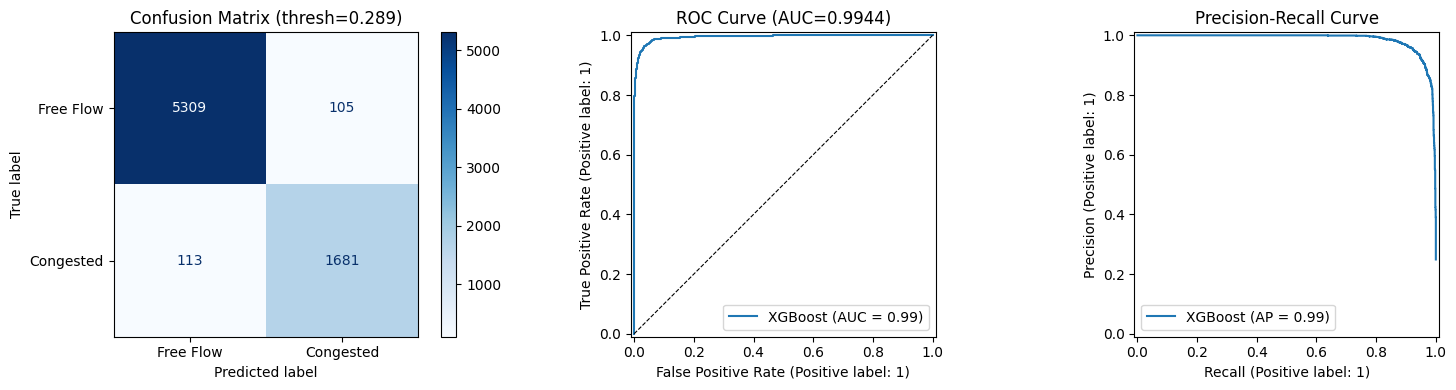

In [18]:
# --------------------------------
# 17. FINAL EVALUATION ON TEST SET
# --------------------------------

test_prob = calibrated_model.predict_proba(X_test)[:, 1]
pred_05   = (test_prob >= 0.50).astype(int)
pred_opt  = (test_prob >= optimal_threshold).astype(int)

acc_05    = accuracy_score(y_test, pred_05)
acc_opt   = accuracy_score(y_test, pred_opt)
roc_auc   = roc_auc_score(y_test, test_prob)
f1_cong   = f1_score(y_test, pred_opt, pos_label=1)

print(f"Accuracy (0.50):   {acc_05*100:.2f}%")
print(f"Accuracy (optimal {optimal_threshold:.3f}): {acc_opt*100:.2f}%")
print(f"ROC-AUC:           {roc_auc:.4f}")
print(f"Congested F1:      {f1_cong:.4f}")
print()
print("=== Classification Report (optimal threshold) ===")
print(classification_report(y_test, pred_opt, target_names=['Free Flow','Congested']))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_opt,
    display_labels=['Free Flow','Congested'],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title(f"Confusion Matrix (thresh={optimal_threshold:.3f})")

RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[1], name=best_name)
axes[1].plot([0,1],[0,1],'k--',lw=0.8)
axes[1].set_title(f"ROC Curve (AUC={roc_auc:.4f})")

PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[2], name=best_name)
axes[2].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.savefig("evaluation_curves.png", dpi=150)
plt.show()

In [19]:
# --------------------------------
# 18. PER-JUNCTION EVALUATION
# --------------------------------

print("=" * 60)
for jct in sorted(data['junction'].unique()):
    jct_int = int(jct)
    mask    = X_test['junction_id'] == jct_int
    n       = mask.sum()
    if n == 0:
        continue
    city = mapping.get(jct, '?')
    print(f"\nJunction {jct_int} ({city}) — {n} test samples")
    print(classification_report(
        y_test[mask], pred_opt[mask],
        target_names=['Free Flow','Congested'],
        zero_division=0
    ))
    auc = roc_auc_score(y_test[mask], test_prob[mask]) if y_test[mask].nunique() > 1 else float('nan')
    print(f"  AUC: {auc:.4f}")
    print("-" * 60)


Junction 1 (Vancouver) — 2151 test samples
              precision    recall  f1-score   support

   Free Flow       0.94      0.90      0.92       634
   Congested       0.96      0.97      0.97      1517

    accuracy                           0.95      2151
   macro avg       0.95      0.94      0.94      2151
weighted avg       0.95      0.95      0.95      2151

  AUC: 0.9917
------------------------------------------------------------

Junction 2 (Portland) — 2207 test samples
              precision    recall  f1-score   support

   Free Flow       0.99      0.99      0.99      2059
   Congested       0.90      0.88      0.89       148

    accuracy                           0.99      2207
   macro avg       0.95      0.94      0.94      2207
weighted avg       0.99      0.99      0.99      2207

  AUC: 0.9966
------------------------------------------------------------

Junction 3 (San Francisco) — 2206 test samples
              precision    recall  f1-score   support

   Fre

In [20]:
# --------------------------------
# 19. TIME-SERIES CROSS-VALIDATION
# --------------------------------
# TimeSeriesSplit always trains on past, validates on future
# Correct for temporal traffic data — StratifiedKFold can mix future into train

if best_name == 'RandomForest':
    cv_pipeline = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   RandomForestClassifier(
            **study.best_params, class_weight='balanced',
            random_state=42, n_jobs=-1
        ))
    ])
else:
    from sklearn.pipeline import Pipeline as SkPipeline
    cv_pipeline = SkPipeline([('clf', best_model)])

tscv = TimeSeriesSplit(n_splits=5)
cv_scores = cross_val_score(
    cv_pipeline, X[features_final], y,
    cv=tscv, scoring='roc_auc', n_jobs=-1
)

print("TimeSeriesSplit CV ROC-AUC scores:", np.round(cv_scores, 4))
print(f"Mean: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

KeyError: "['weather_encoded'] not in index"

In [ ]:
# --------------------------------
# 20. SHAP FEATURE IMPORTANCE
# --------------------------------
# SHAP gives per-prediction, model-agnostic explanations
# More reliable than RF impurity importance (which is biased toward high-cardinality features)

# Use a sample for speed (SHAP on full test set is slow)
shap_sample = X_test.sample(min(500, len(X_test)), random_state=42)

if best_name == 'RandomForest':
    explainer  = shap.TreeExplainer(best_model)
else:
    explainer  = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(shap_sample)

# For binary classification: shap_values is [class0_array, class1_array] for RF
# For XGB/LGBM it may be a single array — handle both
if isinstance(shap_values, list):
    sv = shap_values[1]   # use class-1 (congested) SHAP values
else:
    sv = shap_values

# Summary plot (beeswarm)
plt.figure()
shap.summary_plot(sv, shap_sample, feature_names=features_final, show=False)
plt.title("SHAP Summary — Feature Impact on Congestion Probability")
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches='tight')
plt.show()

# Bar plot (mean |SHAP|)
plt.figure()
shap.summary_plot(sv, shap_sample, feature_names=features_final,
                  plot_type='bar', show=False)
plt.title("SHAP Feature Importance (mean |SHAP|)")
plt.tight_layout()
plt.savefig("shap_bar.png", dpi=150, bbox_inches='tight')
plt.show()

# Single prediction explanation (first test sample)
print("\nSingle prediction SHAP breakdown:")
shap.force_plot(
    explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value,
    sv[0],
    shap_sample.iloc[0],
    feature_names=features_final,
    matplotlib=True
)
plt.tight_layout()
plt.savefig("shap_force.png", dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# --------------------------------
# 21. JUNCTION BASELINE CONGESTION RATES
# --------------------------------
# Stored in artifact so frontend can display without recomputing

junction_baselines = (
    data.groupby('junction')['congested']
    .mean()
    .round(4)
    .to_dict()
)

print("Historical congestion rate per junction:")
for jct, rate in sorted(junction_baselines.items()):
    city = mapping.get(jct, '?')
    print(f"  Junction {int(jct)} ({city}): {rate*100:.1f}%")

In [ ]:
# --------------------------------
# 22. VERSIONED ARTIFACT EXPORT
# --------------------------------

artifact = {
    # Core model
    'model':             calibrated_model,
    'best_model_name':   best_name,

    # Encoding maps
    'freq_map':          freq_map,
    'train_means':       train_means,
    'severity_map':      severity_map,

    # Decision boundary
    'optimal_threshold': optimal_threshold,

    # Junction context
    'junction_city_map':  mapping,
    'junction_baselines': junction_baselines,

    # Feature contract (frontend reads this — no hardcoding needed)
    'features_final':    features_final,

    # Performance metrics
    'metrics': {
        'accuracy':          float(acc_opt),
        'roc_auc':           float(roc_auc),
        'f1_congested':      float(f1_cong),
        'cv_auc_mean':       float(cv_scores.mean()),
        'cv_auc_std':        float(cv_scores.std()),
    },

    # Provenance
    'sklearn_version':   sklearn.__version__,
    'trained_at':        datetime.now().isoformat(),
    'n_train_samples':   int(len(X_train_res)),
    'n_features':        int(len(features_final)),
}

joblib.dump(artifact, 'traffic_model_v2.pkl')
print("Artifact saved: traffic_model_v2.pkl")
print(f"\nKeys: {list(artifact.keys())}")
print(f"\nMetrics:")
for k, v in artifact['metrics'].items():
    print(f"  {k}: {v:.4f}")
print(f"\nFeatures ({len(features_final)}):")
for i, f in enumerate(features_final, 1):
    print(f"  {i:2d}. {f}")

In [ ]:
# --------------------------------
# 23. SAMPLE PREDICTION
# --------------------------------

sample    = X_test.iloc[0:1]
prob      = calibrated_model.predict_proba(sample)[0][1]
predicted = int(prob >= optimal_threshold)
confidence = prob if predicted == 1 else (1 - prob)

jct  = int(sample['junction_id'].values[0])
city = mapping.get(jct, '?')

print("SAMPLE INPUT:")
print(sample[['junction_id','hour_sin','hour_cos','temp_celsius',
              'humidity','vehicles_lag_1h','vehicles_roll3_mean']].to_string())
print()
print(f"Junction:        {jct} ({city})")
print(f"P(congested):    {prob:.4f}")
print(f"Threshold:       {optimal_threshold:.4f}")
print()
print("PREDICTION:", "⚠️  CONGESTED" if predicted == 1 else "✅  FREE FLOW")
print(f"Confidence:      {confidence*100:.1f}%")